# Helsinki: what going green costs in time, money and access

Fourth notebook of the Helsinki pipeline. `02.1` priced every hexagon-to-
hexagon trip per mode in time, money and life-cycle CO₂e, `02.2` built the
amenity layer, `02.3` routed every hexagon to every amenity point on time. This
notebook puts the three currencies side by side and asks, for a household that
wants the access a car gives, what the greener modes cost it.

The **access index** of a hexagon under a budget is the share of the region's
amenities reachable within it, computed per category and averaged over the
eleven categories so that each weighs the same. Time to an amenity is the
point-level door-to-door time of `02.3`; the money and the emissions of the
trip are those of the `02.1` trip to the amenity's hexagon (the car's are
linear in distance, transit fares depend on the zone), which keeps all three
currencies on one trip set.

1. **Access per currency.** The index as a function of a time budget, a money
   cap and a carbon cap per trip, one curve per mode and fleet state.
2. **Matching the car.** The reference is an access level, 20 % of the
   region's amenities, and the budget the car needs to reach it. For every
   hexagon and alternative: the extra minutes of budget and the extra euros
   per trip needed over the car's to reach the same level, the CO₂e avoided
   per trip, and then the cost of that access in the three currencies, mode
   by mode, as the trade-off a household faces.
3. **The frontier across access levels.** The level swept from 5 to 50 %:
   each mode's path in time, money and carbon, and per household the modes
   no other mode beats on all three at once.

| Step | Output |
|---|---|
| 1. Access per currency | Figure |
| 2. Matching the car | `sacrifice.parquet`, hexagon by alternative by car class; figures, maps |
| 3. Frontier | Figures and a dominance table |

In [1]:
import json
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

from cafein._streaming import read_shards
from cafein.emissions import vehicle_class_factors

## Parameters

The reference is an access level: 20 % of the region's amenities, averaged
over the categories. The budget the car needs to reach it is the yardstick,
and the alternatives may spend up to 60 minutes to reach the same level. The
money and carbon caps are applied within a fixed 30-minute window, so that a
zero-emission mode is not credited with the whole city. The value of time and
the carbon price are exploratory constants that turn a time sacrifice into
euros and give the implied price something to be compared with; both are
meant to be varied. The car's money is rebuilt here from its driven
kilometres at 0.36 EUR per kilometre, the shipped 0.25 EUR of 2017 brought to
current euros, so that it sits in the same price year as the fares; `02.1` is
left as it is. The outputs that depend on the reference level carry it
in their name, so that runs at different levels can be compared.

In [2]:
CITY = "helsinki"
RESULTS = Path("/scratch/project_2010423/carbon-advantage") / CITY
METRIC_CRS = "EPSG:3067"

PARAMETERS = {
    "city": CITY,
    "modes": ["walk", "bicycle", "e_bike", "transit", "car"],
    # The access level every mode has to reach, and how long it may take.
    "reference_access": 0.2,
    "max_budget_min": 60,
    # One-way time tolerances of the active modes, applied only when the switch
    # is on. Walking: Yang & Diez-Roux (2012) report a median walking trip of
    # 10 min and 18 % of trips over a mile, so 30 min bounds nearly all
    # utilitarian walks. Bicycle: 30 min at 15.3 km/h is 7.7 km, close to the
    # 7.5 km short-distance threshold of the Dutch cycling literature (Heinen,
    # van Wee & Maat 2010). E-bike: 45 min at 17.4 km/h is 13 km, above the
    # 9.4 km trips e-bike users report against 4.8 km for cyclists (Castro et
    # al. 2019, PASTA); the tolerance is kept in time, as before the speeds of
    # the two modes were separated in cafein 0.30.
    "active_mode_cutoffs_min": {"walk": 30, "bicycle": 30, "e_bike": 45},
    "apply_active_cutoffs": False,
    # The fixed budget under which the money and carbon caps are applied.
    "time_budget_min": 30,
    # The car's running cost per kilometre, replacing the shipped 0.25 EUR2017 of 02.1
    # with its inflation-adjusted value in current euros.
    "car_cost_eur_per_km": 0.36,
    "money_caps_eur": [0, 10, 41],
    "carbon_caps_g": [0, 5000, 51],
    # Exploratory constants: the value of time and a carbon price to compare with.
    "value_of_time_eur_per_h": 10.0,
    "carbon_price_eur_per_kg": 0.1,
    "car_classes": ["car-ICE", "car-BEV"],
}
# Outputs that depend on the reference level carry it in their name.
TAG = f"access{round(PARAMETERS['reference_access'] * 100):02d}"
(RESULTS / f"value_parameters-{TAG}.json").write_text(json.dumps(PARAMETERS, indent=2))

lattice = gpd.read_file(RESULTS / "lattice.gpkg")
taxonomy = json.loads((RESULTS / "poi_taxonomy.json").read_text())["taxonomy"]
CATEGORIES = list(dict.fromkeys(rule["category"] for rule in taxonomy.values()))
MODES = PARAMETERS["modes"]
MODE_COLOURS = {"walk": "#2a78d6", "bicycle": "#1baf7a", "e_bike": "#7a4fbf", "transit": "#eb6834", "car": "#eda100"}
SERIES = {  # label -> (colour key, line style, display name)
    "walk": ("walk", "-", "walk"), "bicycle": ("bicycle", "-", "bicycle"), "e_bike": ("e_bike", "-", "e-bike"),
    "transit": ("transit", "-", "transit"), "transit-bus-bev": ("transit", "--", "transit, electric buses"),
    "car-ICE": ("car", "-", "car"), "car-BEV": ("car", "--", "car, electric"),
}

index = pd.Index(lattice["id"])
population = lattice["population"].to_numpy(dtype=float)
lattice_metric = lattice.to_crs(METRIC_CRS).set_index("id")

## 0. Amenity points and the cost arrays

Every amenity point gets its hexagon (the nearest one for the points in the
margin outside the inhabited lattice). The point-level travel times of `02.3`
become dense hexagon-by-point arrays of minutes, one per mode; the money and
emissions of the `02.1` trip to the point's hexagon are gathered onto the same
shape. A missing time is an amenity outside the mode's cutoff, never reached.
The car's money is its driven kilometres at the notebook's rate rather than
the `02.1` column. The electric car is the same trips at the `car-BEV` factor;
the electric-bus transit run of `02.1` is its own label.

In [3]:
pois = gpd.read_file(RESULTS / "pois.gpkg")
pois["point_id"] = pois["osm_type"].str[0] + pois["osm_id"].astype(str)
points = pois.drop_duplicates("point_id")[["point_id", "geometry"]].to_crs(METRIC_CRS).reset_index(drop=True)
point_index = pd.Index(points["point_id"])

one_hot = (
    pois.assign(one=1.0).pivot_table(index="point_id", columns="category", values="one", aggfunc="max", fill_value=0.0)
    .reindex(index=point_index, columns=CATEGORIES, fill_value=0.0)
)
ONE_HOT = one_hot.to_numpy(dtype=np.float32)
TOTALS = ONE_HOT.sum(axis=0)

hexagons = lattice.to_crs(METRIC_CRS)[["id", "geometry"]]
inside = gpd.sjoin(points, hexagons, predicate="within", how="left")["id"]
nearest = gpd.sjoin_nearest(points, hexagons, how="left")["id"]
point_hexagon = index.get_indexer(inside.where(inside.notna(), nearest.groupby(level=0).first()))
print(f"{len(points):,} amenity points, {(inside.isna()).sum():,} in the margin assigned to the nearest hexagon")


def dense_points(frame, column, scale=1.0):
    '''A hexagon-by-point array of one column, missing where the pair is absent.'''
    array = np.full((len(index), len(point_index)), np.nan, dtype=np.float32)
    rows, columns = index.get_indexer(frame["from_id"]), point_index.get_indexer(frame["to_id"])
    array[rows, columns] = frame[column].to_numpy(dtype=np.float32) * scale
    return array


def dense_hexagons(frame, column, scale=1.0):
    '''A hexagon-by-hexagon array of one column, gathered onto the points' hexagons.'''
    array = np.full((len(index), len(index)), np.nan, dtype=np.float32)
    array[index.get_indexer(frame["from_id"]), index.get_indexer(frame["to_id"])] = frame[column].to_numpy(dtype=np.float32) * scale
    return array[:, point_hexagon]


started = time.time()
resident = pd.read_parquet(RESULTS / "resident_table.parquet")
walk_trips = read_shards(RESULTS / "walk")
car_factor = vehicle_class_factors()[["vehicle", "fuel", "infrastructure", "operations"]].sum(axis=1)

times = {mode: dense_points(read_shards(RESULTS / "amenities" / mode), "travel_time", 1 / 60) for mode in MODES}
if PARAMETERS["apply_active_cutoffs"]:
    for mode, minutes in PARAMETERS["active_mode_cutoffs_min"].items():
        times[mode] = np.where(times[mode] <= minutes, times[mode], np.nan).astype(np.float32)
costs = {}
for label, mode in [("bicycle", "bicycle"), ("e_bike", "e_bike"), ("transit", "transit"), ("transit-bus-bev", "transit"), ("car-ICE", "car")]:
    part = resident.loc[resident["mode"] == label.replace("car-ICE", "car")]
    costs[label] = {"time": times[mode], "money": dense_hexagons(part, "money"), "co2": dense_hexagons(part, "emissions_g"),
                    "km": dense_hexagons(part, "distance_m", 1 / 1000)}
costs["walk"] = {"time": times["walk"], "money": dense_hexagons(walk_trips, "cost_private"), "co2": dense_hexagons(walk_trips, "emissions"),
                 "km": dense_hexagons(walk_trips, "network_distance_m", 1 / 1000)}
car_km = costs["car-ICE"]["km"]
costs["car-ICE"]["money"] = car_km * np.float32(PARAMETERS["car_cost_eur_per_km"])
costs["car-BEV"] = {**costs["car-ICE"], "co2": car_km * np.float32(car_factor["car-BEV"])}
del car_km

# A reached amenity whose hexagon trip is unpriced (a few transit fares, or a
# hexagon pair beyond the 02.1 cutoff) takes the label's median cost.
for label, cost in costs.items():
    reached = ~np.isnan(cost["time"])
    for currency in ["money", "co2", "km"]:
        missing = reached & np.isnan(cost[currency])
        cost[currency] = np.where(missing, np.nanmedian(cost[currency]), cost[currency]).astype(np.float32)
print(f"arrays built in {time.time() - started:.0f} s")

pd.DataFrame({
    label: {"reached_pairs": np.isfinite(c["time"]).sum(), "median_min": np.nanmedian(c["time"]),
            "median_eur": np.nanmedian(np.where(np.isfinite(c["time"]), c["money"], np.nan)),
            "median_g": np.nanmedian(np.where(np.isfinite(c["time"]), c["co2"], np.nan))}
    for label, c in costs.items()
}).T.round(2)

30,989 amenity points, 1,736 in the margin assigned to the nearest hexagon


arrays built in 13 s


,reached_pairs,median_min,median_eur,median_g
bicycle,14583361.0,40.15,0.47,366.07
e_bike,17852318.0,39.13,0.52,277.03
transit,33955970.0,67.67,3.30,1141.44
transit-bus-bev,33955970.0,67.67,3.30,541.75
car-ICE,31989358.0,42.12,7.23,3253.99
walk,1120019.0,41.88,0.10,0.00
car-BEV,31989358.0,42.12,7.23,1406.05


## 1. Access per currency

The population-weighted mean of the access index. The first panel spends time
alone; the other two keep every trip within 30 minutes and cap, per trip, the
money or the carbon it may cost. A zero-emission mode is a flat line in the
carbon panel: the cap never binds.

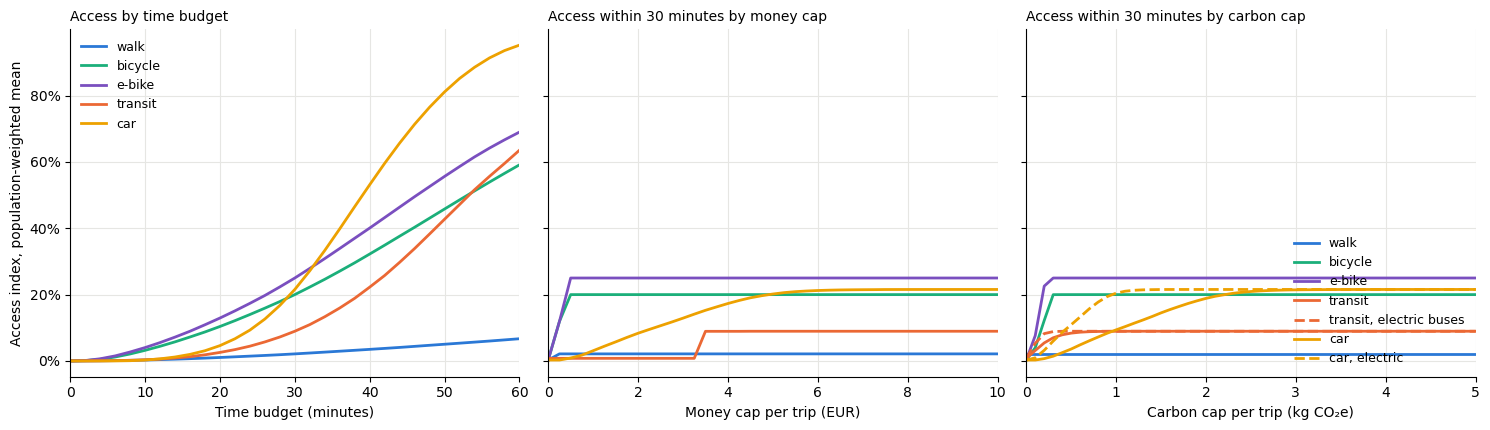

In [4]:
def access_index(mask):
    '''Mean over categories of the share of the region's amenities inside the reached set, per origin.'''
    return ((mask.astype(np.float32) @ ONE_HOT) / TOTALS).mean(axis=1)


def population_mean(values):
    keep = ~np.isnan(values)
    return (values[keep] * population[keep]).sum() / population[keep].sum()


def curve(label, currency, grid, within=None):
    '''Population-weighted access index as the cap on one currency rises.'''
    reach = np.ones_like(costs[label]["time"], dtype=bool) if within is None else costs[label]["time"] <= within
    values = np.nan_to_num(costs[label][currency], nan=np.inf)
    return [population_mean(access_index(reach & (values <= cap))) for cap in grid]


time_grid = np.arange(0, PARAMETERS["max_budget_min"] + 1, 2)
money_grid = np.linspace(*PARAMETERS["money_caps_eur"])
carbon_grid = np.linspace(*PARAMETERS["carbon_caps_g"])
within = PARAMETERS["time_budget_min"]
PANELS = [
    ("time", time_grid, None, "Time budget (minutes)", "Access by time budget"),
    ("money", money_grid, within, "Money cap per trip (EUR)", f"Access within {within} minutes by money cap"),
    ("co2", carbon_grid / 1000, within, "Carbon cap per trip (kg CO₂e)", f"Access within {within} minutes by carbon cap"),
]

figure, axes = plt.subplots(ncols=3, figsize=(15, 4.4), sharey=True)
for axis, (currency, grid, budget, xlabel, title) in zip(axes, PANELS):
    for label, (colour, style, name) in SERIES.items():
        if currency != "co2" and label in ("transit-bus-bev", "car-BEV"):
            continue
        values = curve(label, currency, grid * 1000 if currency == "co2" else grid, within=budget)
        axis.plot(grid, values, color=MODE_COLOURS[colour], linestyle=style, linewidth=2, label=name)
    axis.set_title(title, fontsize=10, loc="left")
    axis.set_xlabel(xlabel)
    axis.set_xlim(grid[0], grid[-1])
    axis.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axis.grid(color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Access index, population-weighted mean")
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
axes[2].legend(frameon=False, fontsize=9, loc="lower right")
figure.tight_layout()

## 2. Matching the car

Per hexagon, the target is the reference access level, the same share of the
region's amenities everywhere. For each mode, the car included, the smallest
time budget on a one-minute grid that reaches the level is the *matching
budget*; a hexagon that cannot reach it within the maximum is *unmatched*.
The car's matching budget is the yardstick, and three quantities follow for
each alternative:

- **extra time**, the alternative's matching budget minus the car's: the
  minutes a household has to add to its travel budget to keep the car's reach;
- **extra money**, the mean fare or running cost of the trips within the
  alternative's matching budget minus the same for the car's trips within its
  own: the euros per trip;
- **CO₂e avoided**, the same difference in life-cycle emissions per trip.

Dividing the first two by the third gives the minutes and the euros per
kilogram, and with the value of time both fold into the **implied carbon
price**: the euros a household gives up per kilogram when it takes the
greener mode. A negative extra time means the alternative needs a shorter
budget than the car, which happens where the car's parking search and rush
delays outweigh its speed; a negative implied price means the greener mode is
cheaper before carbon counts. The car is taken in both fleet states; against
an electric car, transit may avoid nothing, and those pairs stay missing. A
hexagon where the car itself cannot reach the level within the maximum has no
yardstick and stays unmatched for every alternative.

In [5]:
reference_access = PARAMETERS["reference_access"]
budget_grid = np.arange(1, PARAMETERS["max_budget_min"] + 1)
VALUE_OF_TIME = PARAMETERS["value_of_time_eur_per_h"]
ALTERNATIVES = ["walk", "bicycle", "e_bike", "transit", "transit-bus-bev"]
SHOWN_ALTERNATIVES = ["walk", "bicycle", "e_bike", "transit"]

started = time.time()
index_by_budget = {
    label: np.stack([access_index(cost["time"] <= budget) for budget in budget_grid]) for label, cost in costs.items()
}
print(f"access index on the budget grid for every label in {time.time() - started:.0f} s")


def matching_budget(label, target):
    '''The smallest budget at which the access index reaches the target, per origin; missing when never.'''
    enough = index_by_budget[label] >= target[None, :]
    return np.where(enough.any(axis=0), budget_grid[enough.argmax(axis=0)], np.nan).astype(float)


def trip_means(label, budgets):
    '''Mean time, money and emissions over the amenities within each origin's budget.'''
    reach = costs[label]["time"] <= np.nan_to_num(np.asarray(budgets, dtype=np.float32), nan=-1.0)[:, None]
    count = reach.sum(axis=1)
    safe = np.where(count > 0, count, 1)
    return pd.DataFrame({
        currency: np.where(count > 0, (np.nan_to_num(costs[label][currency]) * reach).sum(axis=1) / safe, np.nan)
        for currency in ["time", "money", "co2", "km"]
    })


target = np.full(len(index), reference_access)
budgets = {label: matching_budget(label, target) for label in costs}
trips_at_match = {label: trip_means(label, budgets[label]) for label in costs}
car_trips = {car_class: trips_at_match[car_class] for car_class in PARAMETERS["car_classes"]}

rows = []
for alternative in ALTERNATIVES:
    budget, trips = budgets[alternative], trips_at_match[alternative]
    for car_class in PARAMETERS["car_classes"]:
        car = car_trips[car_class]
        rows.append(pd.DataFrame({
            "id": index, "alternative": alternative, "car_class": car_class,
            "target_access": target, "matching_budget_min": budget, "car_budget_min": budgets[car_class],
            "extra_time_min": budget - budgets[car_class],
            "extra_money_eur": trips["money"] - car["money"],
            "delta_trip_time_min": trips["time"] - car["time"],
            "saved_co2_kg": (car["co2"] - trips["co2"]) / 1000,
            "car_money_eur": car["money"],
            "car_co2_kg": car["co2"] / 1000,
        }))
sacrifice = pd.concat(rows, ignore_index=True)
sacrifice["matched"] = sacrifice["matching_budget_min"].notna() & sacrifice["car_budget_min"].notna()
saves = sacrifice["matched"] & (sacrifice["saved_co2_kg"] > 0)
sacrifice["min_per_kg"] = np.where(saves, sacrifice["extra_time_min"] / sacrifice["saved_co2_kg"], np.nan)
sacrifice["eur_per_kg"] = np.where(saves, sacrifice["extra_money_eur"] / sacrifice["saved_co2_kg"], np.nan)
sacrifice["implied_price_eur_per_kg"] = np.where(
    saves, (sacrifice["extra_time_min"] / 60 * VALUE_OF_TIME + sacrifice["extra_money_eur"]) / sacrifice["saved_co2_kg"], np.nan)
sacrifice["population"] = sacrifice["id"].map(lattice.set_index("id")["population"])
sacrifice.to_parquet(RESULTS / f"sacrifice-{TAG}.parquet", index=False)


def weighted_median(values, weights):
    '''The population-weighted median, missing values excluded.'''
    keep = values.notna()
    values, weights = values[keep].to_numpy(), weights[keep].to_numpy()
    if len(values) == 0:
        return np.nan
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order])
    return values[order][np.searchsorted(cumulative, cumulative[-1] / 2)]


def median_of(column, frame):
    return frame.groupby(["car_class", "alternative"], observed=True)[[column, "population"]].apply(
        lambda part: weighted_median(part[column], part["population"]))


matched = sacrifice.loc[sacrifice["matched"]]
summary = pd.DataFrame({
    "residents_matched": sacrifice.groupby(["car_class", "alternative"])[["matched", "population"]].apply(
        lambda part: (part["matched"] * part["population"]).sum() / part["population"].sum()),
    "car_budget_min": median_of("car_budget_min", matched),
    "matching_budget_min": median_of("matching_budget_min", matched),
    "extra_time_min": median_of("extra_time_min", matched),
    "extra_money_eur": median_of("extra_money_eur", matched),
    "saved_co2_kg": median_of("saved_co2_kg", matched),
    "min_per_kg": median_of("min_per_kg", matched),
    "eur_per_kg": median_of("eur_per_kg", matched),
    "implied_price_eur_per_kg": median_of("implied_price_eur_per_kg", matched),
})
car_budget = budgets["car-ICE"]
car_reaches = population[~np.isnan(car_budget)].sum() / population.sum()
print(f"the car reaches {reference_access:.0%} access within {PARAMETERS['max_budget_min']} minutes for "
      f"{car_reaches:.1%} of residents; population-weighted median budget "
      f"{weighted_median(pd.Series(car_budget), pd.Series(population)):.0f} min")
summary.round(2)

access index on the budget grid for every label in 13 s


the car reaches 20% access within 60 minutes for 99.8% of residents; population-weighted median budget 30 min


residents_matched  car_budget_min  \
car_class alternative                                          
car-BEV   bicycle                       0.97            30.0   
          e_bike                        0.99            30.0   
          transit                       0.96            30.0   
          transit-bus-bev               0.96            30.0   
          walk                          0.09            23.0   
car-ICE   bicycle                       0.97            30.0   
          e_bike                        0.99            30.0   
          transit                       0.96            30.0   
          transit-bus-bev               0.96            30.0   
          walk                          0.09            23.0   

                           matching_budget_min  extra_time_min  \
car_class alternative                                            
car-BEV   bicycle                         33.0             2.0   
          e_bike                          30.0            -1.0   
          transit                         42.0            10.0   
          transit-bus-bev                 42.0            10.0   
          walk                            51.0            26.0   
car-ICE   bicycle                         33.0             2.0   
          e_bike                          30.0            -1.0   
          transit                         42.0            10.0   
          transit-bus-bev                 42.0            10.0   
          walk                            51.0            26.0   

                           extra_money_eur  saved_co2_kg  min_per_kg  \
car_class alternative                                                  
car-BEV   bicycle                    -2.66          0.36        6.16   
          e_bike                     -2.68          0.43       -2.70   
          transit                     0.28          0.13       52.14   
          transit-bus-bev             0.28          0.37       27.90   
          walk                       -0.80          0.17      142.76   
car-ICE   bicycle                    -2.66          1.11        2.07   
          e_bike                     -2.68          1.18       -0.99   
          transit                     0.28          0.85       11.73   
          transit-bus-bev             0.28          1.12        9.37   
          walk                       -0.80          0.40       61.69   

                           eur_per_kg  implied_price_eur_per_kg  
car_class alternative                                            
car-BEV   bicycle               -7.26                     -6.10  
          e_bike                -6.18                     -6.62  
          transit                2.66                     13.53  
          transit-bus-bev        0.77                      5.62  
          walk                  -4.71                     19.11  
car-ICE   bicycle               -2.39                     -2.06  
          e_bike                -2.26                     -2.43  
          transit                0.32                      2.55  
          transit-bus-bev        0.25                      1.91  
          walk                  -2.03                      8.26

### The extra time, the extra money and the extra carbon

The three sacrifices against today's car, one currency at a time and before
any of them is divided by another. The curves are distributions over
residents; residents to the right of a curve's end are unmatched, because
the alternative or the car itself cannot reach the level within 60 minutes.
The maps read the same three quantities on the lattice, matched hexagons
only. Everywhere the sign is the alternative's cost over the car's: positive
minutes and euros are what a household gives up, positive kilograms would be
carbon it adds, so a negative carbon value is the avoided CO₂e. Transit pays
a single ticket per trip while the car pays only its running cost, which is
why its money is positive even where it is faster than the car.

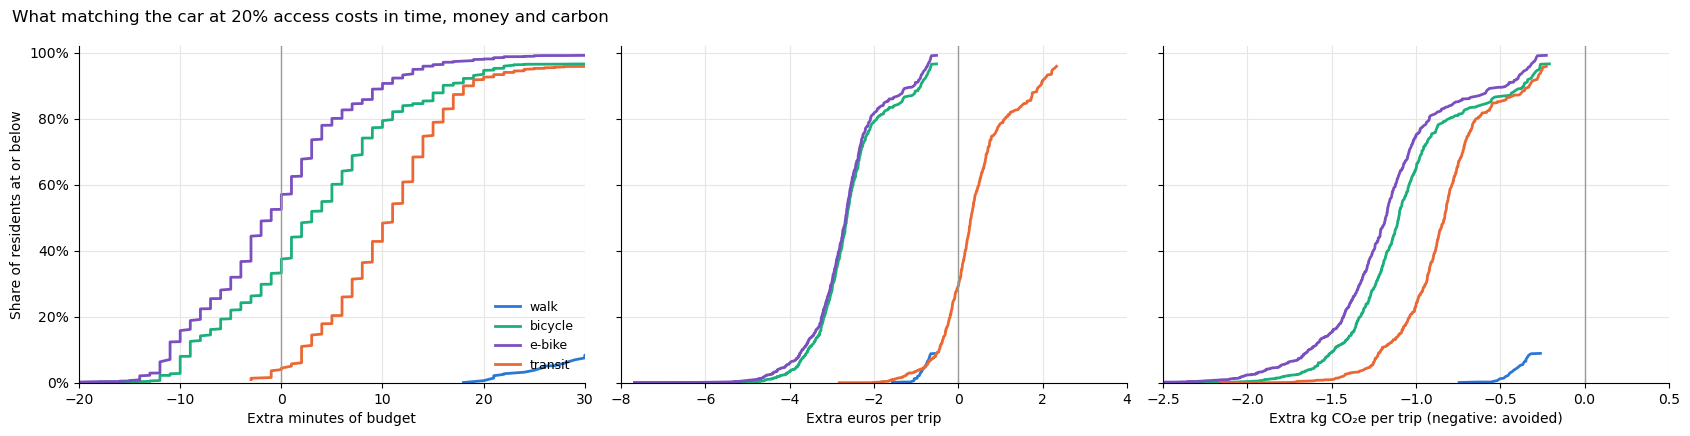

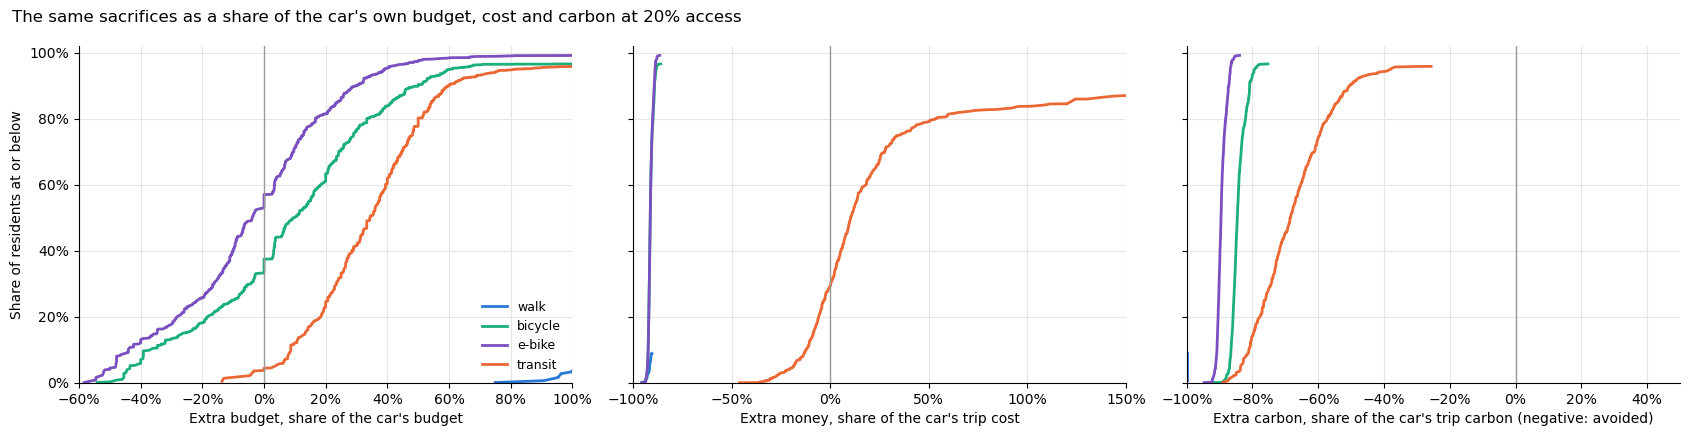

In [6]:
def weighted_cdf(values, weights):
    '''Share of the population at or below each value, as a step curve.'''
    keep = values.notna()
    values, weights = values[keep].to_numpy(), weights[keep].to_numpy()
    order = np.argsort(values)
    return values[order], np.cumsum(weights[order]) / weights.sum()


def plot_cdfs(axis, frame, column, alternatives):
    for alternative in alternatives:
        part = frame.loc[frame["alternative"] == alternative]
        x, y = weighted_cdf(part[column], part["population"])
        if len(x) == 0:
            continue
        # The curve ends at the share of residents with a value: matched, and saving carbon where per kg.
        y = y * (part[column].notna() * part["population"]).sum() / part["population"].sum()
        colour, style, name = SERIES[alternative]
        axis.plot(x, y, color=MODE_COLOURS[colour], linestyle=style, linewidth=2, label=name)
    axis.axvline(0, color="#9a9a96", linewidth=1)
    axis.set_ylim(0, 1.02)
    axis.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axis.grid(color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)


sacrifice["extra_co2_kg"] = -sacrifice["saved_co2_kg"]
CURRENCIES = [  # column, label, axis limits of the curves, colour limits of the maps
    ("extra_time_min", "Extra minutes of budget", (-20, 30), (-15.0, 30.0)),
    ("extra_money_eur", "Extra euros per trip", (-8, 4), (-4.0, 4.0)),
    ("extra_co2_kg", "Extra kg CO₂e per trip (negative: avoided)", (-2.5, 0.5), (-2.0, 0.5)),
]
against_ice = sacrifice.loc[sacrifice["car_class"] == "car-ICE"]
figure, axes = plt.subplots(ncols=3, figsize=(17, 4.4), sharey=True)
for axis, (column, label, limits, _) in zip(axes, CURRENCIES):
    plot_cdfs(axis, against_ice, column, SHOWN_ALTERNATIVES)
    axis.set_xlim(*limits)
    axis.set_xlabel(label)
axes[0].set_ylabel("Share of residents at or below")
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
figure.suptitle(f"What matching the car at {reference_access:.0%} access costs in time, money and carbon", x=0.01, ha="left")
figure.tight_layout()

# The same three sacrifices relative to the car's own value in the hexagon:
# a share of the car's budget, of its trip cost and of its trip carbon.
sacrifice["extra_time_share"] = sacrifice["extra_time_min"] / sacrifice["car_budget_min"]
sacrifice["extra_money_share"] = sacrifice["extra_money_eur"] / sacrifice["car_money_eur"]
sacrifice["extra_co2_share"] = sacrifice["extra_co2_kg"] / sacrifice["car_co2_kg"]
RELATIVE = [
    ("extra_time_share", "Extra budget, share of the car's budget", (-0.6, 1.0)),
    ("extra_money_share", "Extra money, share of the car's trip cost", (-1.0, 1.5)),
    ("extra_co2_share", "Extra carbon, share of the car's trip carbon (negative: avoided)", (-1.0, 0.5)),
]
against_ice = sacrifice.loc[sacrifice["car_class"] == "car-ICE"]
figure, axes = plt.subplots(ncols=3, figsize=(17, 4.4), sharey=True)
for axis, (column, label, limits) in zip(axes, RELATIVE):
    plot_cdfs(axis, against_ice, column, SHOWN_ALTERNATIVES)
    axis.set_xlim(*limits)
    axis.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axis.set_xlabel(label)
axes[0].set_ylabel("Share of residents at or below")
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
figure.suptitle(f"The same sacrifices as a share of the car's own budget, cost and carbon at {reference_access:.0%} access", x=0.01, ha="left")
figure.tight_layout()

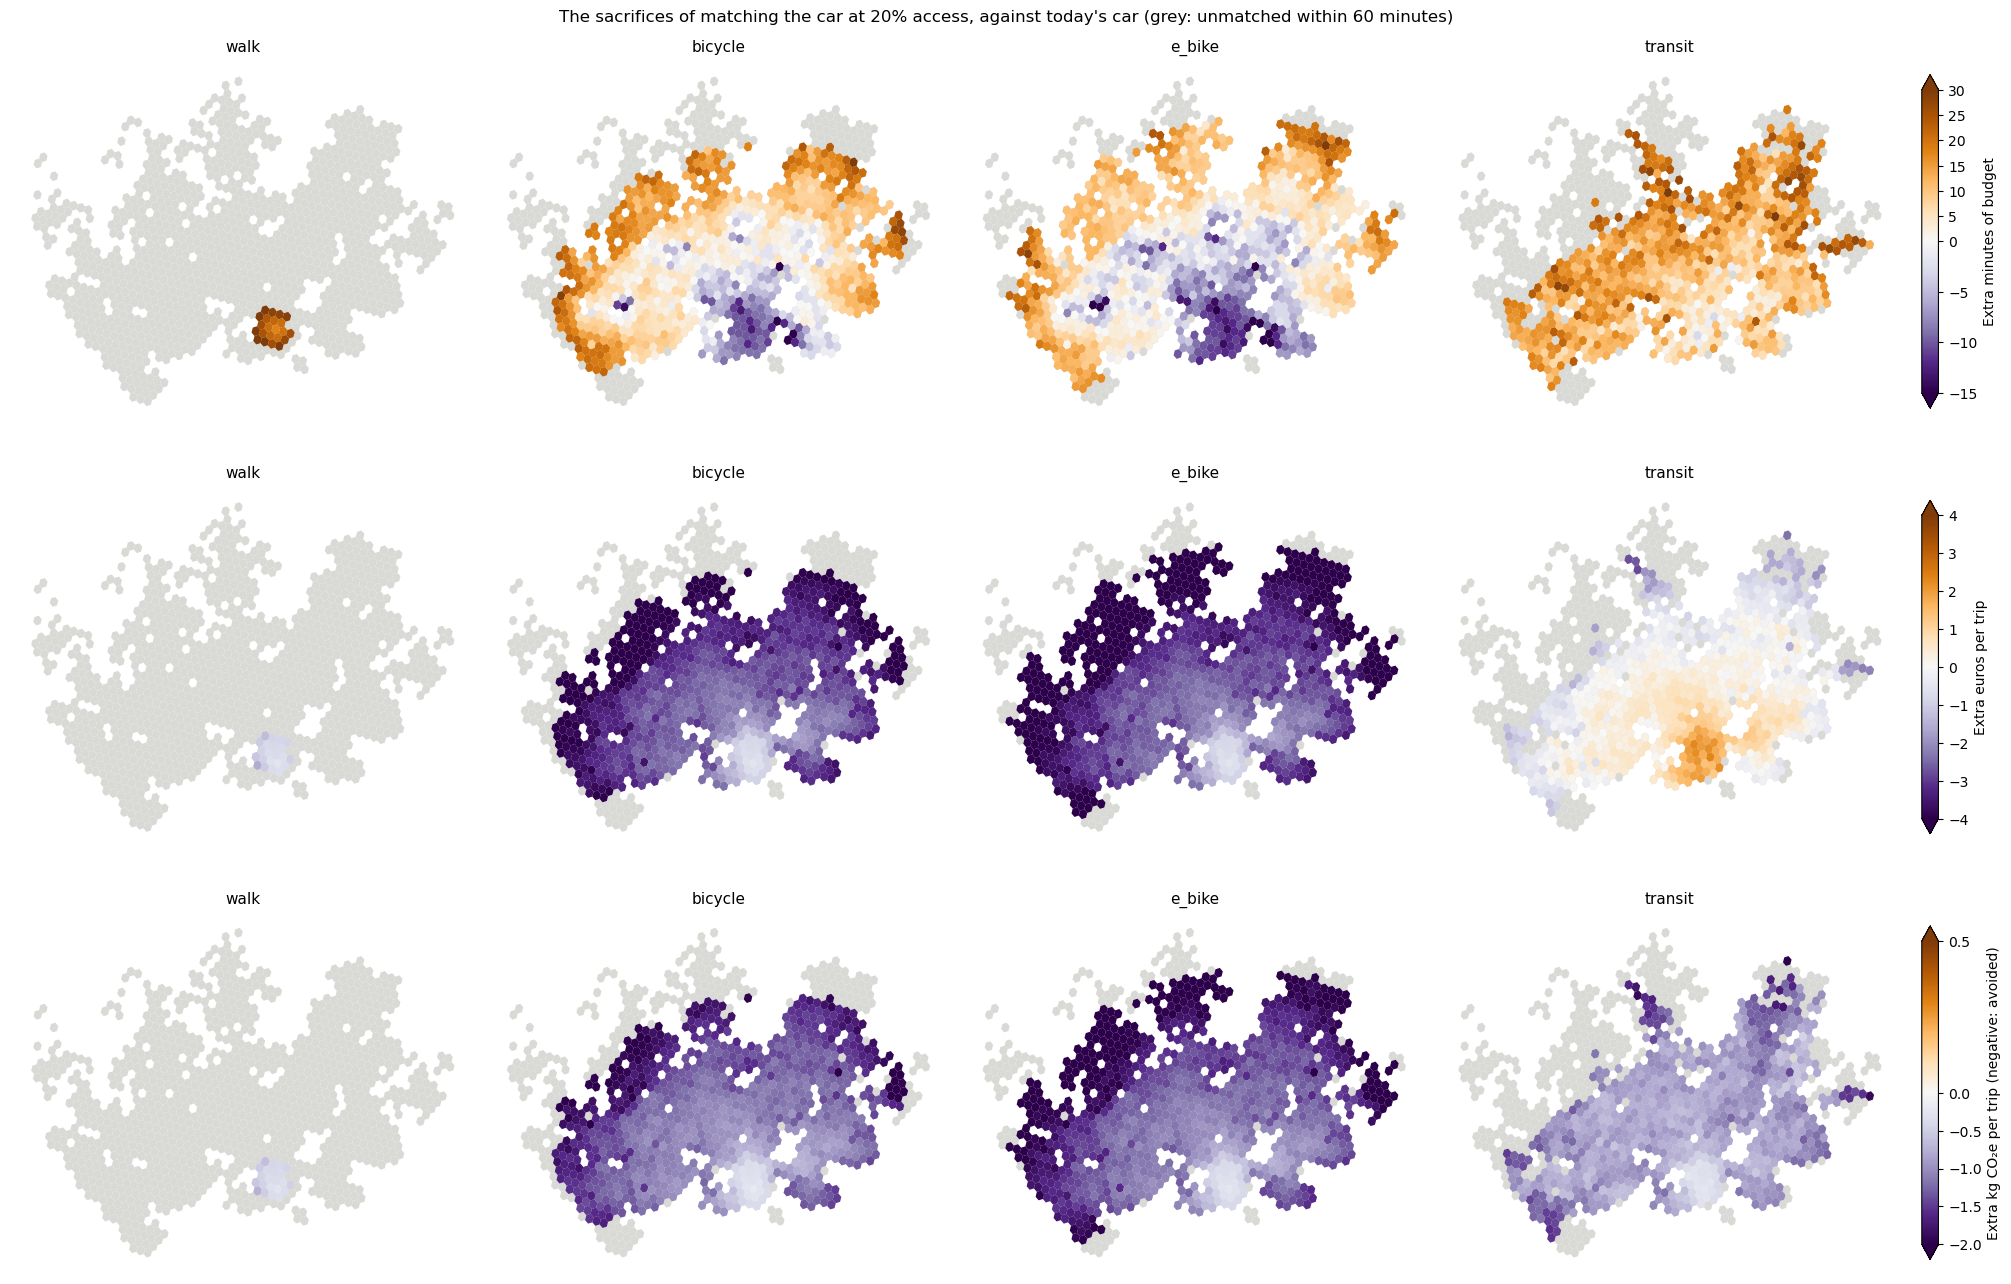

In [7]:
figure, axes = plt.subplots(nrows=len(CURRENCIES), ncols=len(SHOWN_ALTERNATIVES), figsize=(5 * len(SHOWN_ALTERNATIVES), 13), layout="constrained")
for row, (column, label, _, limits) in zip(axes, CURRENCIES):
    norm = TwoSlopeNorm(vmin=limits[0], vcenter=0, vmax=limits[1])
    for axis, alternative in zip(row, SHOWN_ALTERNATIVES):
        part = against_ice.loc[against_ice["alternative"] == alternative].set_index("id")
        frame = lattice_metric.assign(value=part[column].where(part["matched"]).clip(*limits))
        frame.plot(ax=axis, color="#d9d9d6", linewidth=0)
        frame.dropna(subset=["value"]).plot(ax=axis, column="value", cmap="PuOr_r", norm=norm, linewidth=0)
        axis.set_title(alternative, fontsize=11)
        axis.set_axis_off()
    colourbar = figure.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="PuOr_r"), ax=row.tolist(), shrink=0.8, pad=0.01, extend="both")
    colourbar.set_label(label)
figure.suptitle(f"The sacrifices of matching the car at {reference_access:.0%} access, against today's car "
                f"(grey: unmatched within {PARAMETERS['max_budget_min']} minutes)");

### The spread of the sacrifices, against both cars

The same three quantities as box plots, one row per car the alternative is
measured against. Boxes are the population-weighted quartiles over the matched
hexagons, whiskers the 5th and 95th percentiles. The time and the money do not
depend on the car's powertrain, so only the carbon row changes against the
electric car; the table reads the medians and quartiles.

p05    p25  median    p75    p95
against       alternative measure                                            
car           walk        extra_time_min   20.15  21.59   26.00  29.27  31.33
                          extra_money_eur  -1.05  -0.92   -0.80  -0.71  -0.66
                          extra_co2_kg     -0.52  -0.45   -0.39  -0.35  -0.32
              bicycle     extra_time_min  -10.00  -4.00    2.00   8.00  18.00
                          extra_money_eur  -3.81  -3.08   -2.66  -2.26  -0.82
                          extra_co2_kg     -1.60  -1.28   -1.11  -0.94  -0.33
              e_bike      extra_time_min  -12.00  -7.00   -1.00   4.00  13.00
                          extra_money_eur  -4.10  -3.12   -2.68  -2.27  -0.82
                          extra_co2_kg     -1.81  -1.38   -1.18  -1.00  -0.36
              transit     extra_time_min    1.00   6.00   10.00  14.00  19.00
                          extra_money_eur  -0.77  -0.13    0.28   0.74   1.99
                          extra_co2_kg     -1.27  -1.00   -0.85  -0.71  -0.31
car, electric walk        extra_time_min   20.15  21.59   26.00  29.27  31.33
                          extra_money_eur  -1.05  -0.92   -0.80  -0.71  -0.66
                          extra_co2_kg     -0.22  -0.19   -0.17  -0.15  -0.14
              bicycle     extra_time_min  -10.00  -4.00    2.00   8.00  18.00
                          extra_money_eur  -3.81  -3.08   -2.66  -2.26  -0.82
                          extra_co2_kg     -0.53  -0.43   -0.36  -0.31  -0.10
              e_bike      extra_time_min  -12.00  -7.00   -1.00   4.00  13.00
                          extra_money_eur  -4.10  -3.12   -2.68  -2.27  -0.82
                          extra_co2_kg     -0.65  -0.51   -0.43  -0.36  -0.12
              transit     extra_time_min    1.00   6.00   10.00  14.00  19.00
                          extra_money_eur  -0.77  -0.13    0.28   0.74   1.99
                          extra_co2_kg     -0.34  -0.22   -0.13  -0.05   0.11

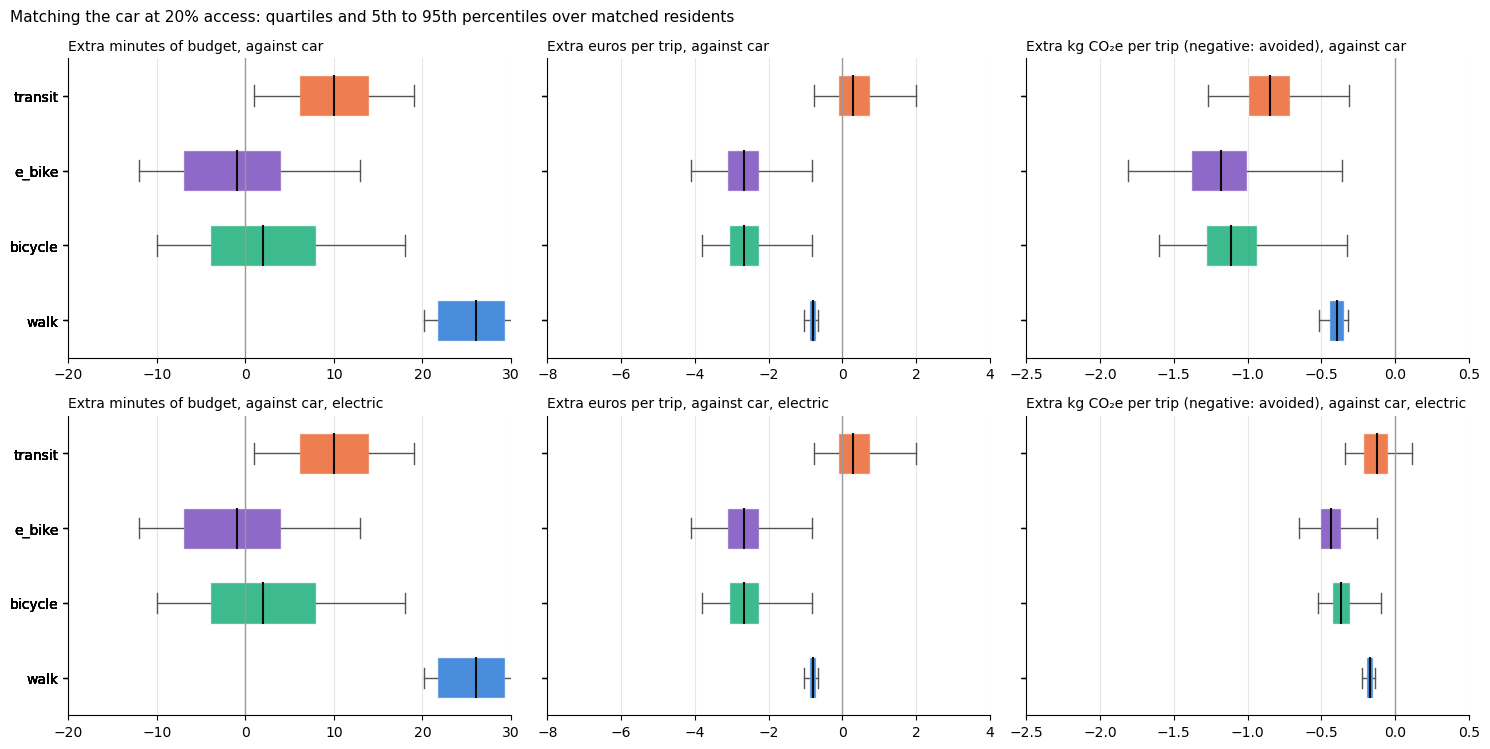

In [8]:
def weighted_quantiles(values, weights, probabilities):
    '''Population-weighted quantiles, missing values excluded.'''
    keep = values.notna()
    values, weights = values[keep].to_numpy(dtype=float), weights[keep].to_numpy(dtype=float)
    if len(values) == 0:
        return [np.nan] * len(probabilities)
    order = np.argsort(values)
    values, weights = values[order], weights[order]
    cumulative = (np.cumsum(weights) - 0.5 * weights) / weights.sum()
    return list(np.interp(probabilities, cumulative, values))


PROBABILITIES = [0.05, 0.25, 0.5, 0.75, 0.95]
matched = sacrifice.loc[sacrifice["matched"]]
rows = []
for car_class in PARAMETERS["car_classes"]:
    for alternative in SHOWN_ALTERNATIVES:
        part = matched.loc[(matched["car_class"] == car_class) & (matched["alternative"] == alternative)]
        for column, label, _, _ in CURRENCIES:
            quantiles = weighted_quantiles(part[column], part["population"], PROBABILITIES)
            rows.append({"against": SERIES[car_class][2], "alternative": alternative, "measure": column,
                         **dict(zip(["p05", "p25", "median", "p75", "p95"], quantiles))})
spread = pd.DataFrame(rows).set_index(["against", "alternative", "measure"])

figure, axes = plt.subplots(nrows=len(PARAMETERS["car_classes"]), ncols=len(CURRENCIES), figsize=(15, 7.6), sharey=True)
for row, car_class in zip(axes, PARAMETERS["car_classes"]):
    for axis, (column, label, limits, _) in zip(row, CURRENCIES):
        stats = []
        for alternative in SHOWN_ALTERNATIVES:
            entry = spread.loc[(SERIES[car_class][2], alternative, column)]
            stats.append({"label": alternative, "whislo": entry["p05"], "q1": entry["p25"], "med": entry["median"],
                          "q3": entry["p75"], "whishi": entry["p95"], "fliers": []})
        boxes = axis.bxp(stats, vert=False, showfliers=False, widths=0.55, patch_artist=True,
                         medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                         whiskerprops={"color": "#55554f"}, capprops={"color": "#55554f"})
        for patch, alternative in zip(boxes["boxes"], SHOWN_ALTERNATIVES):
            patch.set_facecolor(MODE_COLOURS[alternative])
            patch.set_edgecolor("#ffffff")
            patch.set_alpha(0.85)
        axis.axvline(0, color="#9a9a96", linewidth=1)
        axis.set_xlim(*limits)
        axis.set_title(f"{label}, against {SERIES[car_class][2]}", fontsize=10, loc="left")
        axis.grid(axis="x", color="#e6e6e3", linewidth=0.8)
        axis.spines[["top", "right"]].set_visible(False)
        axis.invert_yaxis()
figure.suptitle(f"Matching the car at {reference_access:.0%} access: quartiles and 5th to 95th percentiles over matched residents",
                x=0.01, ha="left", fontsize=11)
figure.tight_layout()

spread.round(2)

### The cost of access, mode by mode

The same numbers read as a cost of access rather than as a difference: what
a household pays, in time, money and carbon, to reach the reference share
of the region's amenities by each mode. Per hexagon and mode the budget is
the matching budget of section 2 and the trip is the mean trip inside it;
the table and the first figure give the population-weighted medians over
the residents the mode serves, and the sentences below the table read them
out. The second figure is the trade-off itself: every hexagon is a faint
point at its money and carbon per trip, the medians are the labelled
markers, and the label carries the minutes. A mode to the lower left of
the car reaches the same access for less money and less carbon; the box
plots above quantify the gaps household by household.

By walk, reaching 20% of the region's amenities takes a 51-minute budget; the typical trip inside it is 1.7 km, 28 min, 0.07 EUR and 0 g CO₂e (9% of residents reach the level).
By bicycle, reaching 20% of the region's amenities takes a 33-minute budget; the typical trip inside it is 5.4 km, 22 min, 0.25 EUR and 199 g CO₂e (97% of residents reach the level).
By e-bike, reaching 20% of the region's amenities takes a 30-minute budget; the typical trip inside it is 5.5 km, 19 min, 0.26 EUR and 137 g CO₂e (99% of residents reach the level).
By transit, reaching 20% of the region's amenities takes a 42-minute budget; the typical trip inside it is 6.9 km, 33 min, 3.21 EUR and 407 g CO₂e (96% of residents reach the level).
By transit, electric buses, reaching 20% of the region's amenities takes a 42-minute budget; the typical trip inside it is 6.9 km, 33 min, 3.21 EUR and 189 g CO₂e (96% of residents reach the level).
By car, reaching 20% of the region's amenities takes a 30-minute budget; the

,residents_reaching,budget_min,trip_min,trip_km,eur_per_trip,kg_per_trip
mode,,,,,,
walk,0.09,51.0,28.39,1.71,0.07,0.00
bicycle,0.97,33.0,21.97,5.39,0.25,0.20
e-bike,0.99,30.0,19.34,5.46,0.26,0.14
transit,0.96,42.0,32.78,6.90,3.21,0.41
"transit, electric buses",0.96,42.0,32.78,6.90,3.21,0.19
car,1.00,30.0,24.71,8.18,2.94,1.32
"car, electric",1.00,30.0,24.71,8.18,2.94,0.57


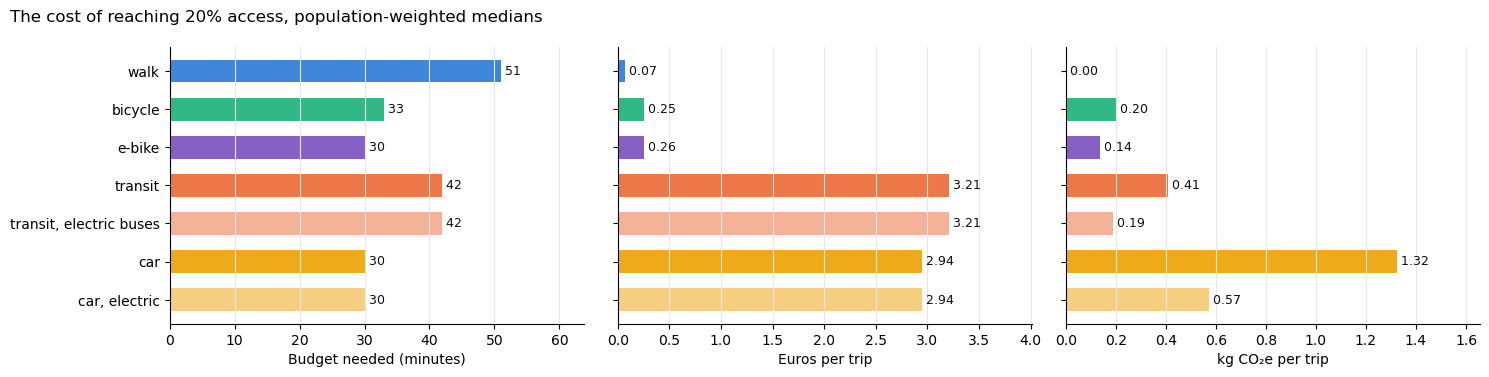

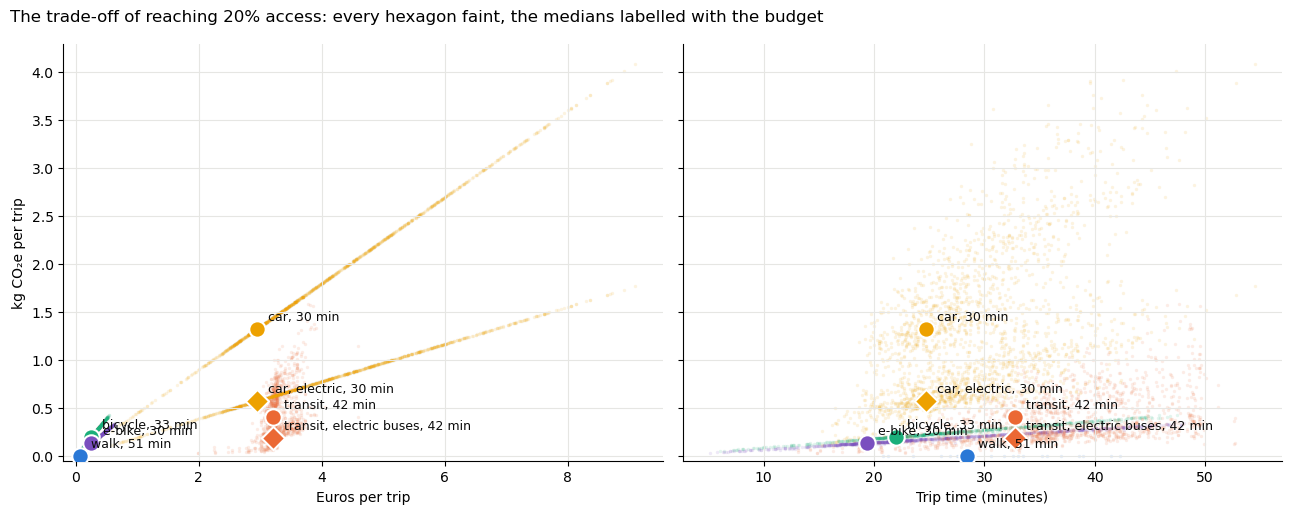

In [9]:
ACCESS_LABELS = ["walk", "bicycle", "e_bike", "transit", "transit-bus-bev", "car-ICE", "car-BEV"]
weights = pd.Series(population)
access_cost = pd.DataFrame([{
    "mode": SERIES[label][2],
    "residents_reaching": population[~np.isnan(budgets[label])].sum() / population.sum(),
    "budget_min": weighted_median(pd.Series(budgets[label]), weights),
    "trip_min": weighted_median(trips_at_match[label]["time"], weights),
    "trip_km": weighted_median(trips_at_match[label]["km"], weights),
    "eur_per_trip": weighted_median(trips_at_match[label]["money"], weights),
    "kg_per_trip": weighted_median(trips_at_match[label]["co2"] / 1000, weights),
} for label in ACCESS_LABELS]).set_index("mode")

for mode, row in access_cost.iterrows():
    print(f"By {mode}, reaching {reference_access:.0%} of the region's amenities takes a {row['budget_min']:.0f}-minute budget; "
          f"the typical trip inside it is {row['trip_km']:.1f} km, {row['trip_min']:.0f} min, {row['eur_per_trip']:.2f} EUR "
          f"and {row['kg_per_trip'] * 1000:.0f} g CO₂e ({row['residents_reaching']:.0%} of residents reach the level).")

COST_PANELS = [("budget_min", "Budget needed (minutes)", "{:.0f}"), ("eur_per_trip", "Euros per trip", "{:.2f}"), ("kg_per_trip", "kg CO₂e per trip", "{:.2f}")]
figure, axes = plt.subplots(ncols=3, figsize=(15, 3.8), sharey=True)
positions = np.arange(len(ACCESS_LABELS))
for axis, (column, label, pattern) in zip(axes, COST_PANELS):
    values = access_cost[column].to_numpy()
    colours = [MODE_COLOURS[SERIES[l][0]] for l in ACCESS_LABELS]
    alphas = [0.5 if SERIES[l][1] == "--" else 0.9 for l in ACCESS_LABELS]
    for position, value, colour, alpha in zip(positions, values, colours, alphas):
        axis.barh(position, value, color=colour, alpha=alpha, height=0.6)
        if np.isfinite(value):
            axis.text(value, position, " " + pattern.format(value), va="center", fontsize=9, color="#0b0b0b")
    axis.set_xlabel(label)
    axis.set_xlim(0, np.nanmax(values) * 1.25)
    axis.grid(axis="x", color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(positions, access_cost.index)
axes[0].invert_yaxis()
figure.suptitle(f"The cost of reaching {reference_access:.0%} access, population-weighted medians", x=0.01, ha="left")
figure.tight_layout()

figure, axes = plt.subplots(ncols=2, figsize=(13, 5.2), sharey=True)
for axis, (column, xlabel) in zip(axes, [("money", "Euros per trip"), ("time", "Trip time (minutes)")]):
    for label in ACCESS_LABELS:
        trips = trips_at_match[label]
        colour = MODE_COLOURS[SERIES[label][0]]
        axis.scatter(trips[column], trips["co2"] / 1000, s=6, color=colour, alpha=0.12, linewidths=0)
    for label in ACCESS_LABELS:
        row = access_cost.loc[SERIES[label][2]]
        x = row["eur_per_trip"] if column == "money" else row["trip_min"]
        colour = MODE_COLOURS[SERIES[label][0]]
        axis.scatter(x, row["kg_per_trip"], s=140, color=colour, edgecolor="#ffffff", linewidth=1.5, zorder=3,
                     marker="o" if SERIES[label][1] == "-" else "D")
        axis.annotate(f"{SERIES[label][2]}, {row['budget_min']:.0f} min", (x, row["kg_per_trip"]), xytext=(8, 6),
                      textcoords="offset points", fontsize=9, color="#0b0b0b", zorder=4)
    axis.set_xlabel(xlabel)
    axis.grid(color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("kg CO₂e per trip")
axes[0].set_xlim(left=-0.2)
axes[0].set_ylim(bottom=-0.05)
figure.suptitle(f"The trade-off of reaching {reference_access:.0%} access: every hexagon faint, the medians labelled with the budget",
                x=0.01, ha="left")
figure.tight_layout()

access_cost.round(2)

## 3. The frontier across access levels

Section 2 fixes one access level. Sweeping the level from 5 to 50 % of the
region's amenities turns each mode into a path: the budget, the euros and
the kilograms per trip it takes to reach every level, population-weighted
medians as before. Drawn in two planes, time against carbon and money
against carbon, the paths are the frontiers of the modes, and the regional
frontier is their lower-left envelope: at any level the modes on it are the
ones no other mode beats on both axes.

The per-household version uses all three currencies at once. For a hexagon
and a level, a mode is *dominated* when another mode reaches the level with
no more minutes, no more euros and no fewer kilograms avoided, and strictly
better on at least one; a mode that does not reach the level within the
maximum is dominated by any that does. The modes left are the household's
*efficient set*: the ones it can choose without being worse off on every
currency. The share of residents for whom each mode is efficient, across
levels and under two fleet states, quantifies the interaction of the three
currencies; the table reads the pairwise contests against the car at the
reference level, where an alternative counts as cleaner only when it saves
at least a quarter of a kilogram per trip, so that the margin, not the mere
win, is what the car's powertrain moves.

costs on the level grid in 41 s
Shares of all residents at 20% access. The car's time and money do not depend on its powertrain, so only the carbon columns move between the two car classes; an alternative counts as cleaner when it saves at least 0.25 kg per trip.


both_reach  less_time  less_money  \
against       alternative                                                  
car           walk                           0.09       0.00        0.09   
              bicycle                        0.97       0.33        0.97   
              e-bike                         0.99       0.52        0.99   
              transit                        0.96       0.04        0.29   
              transit, electric buses        0.96       0.04        0.29   
car, electric walk                           0.09       0.00        0.09   
              bicycle                        0.97       0.33        0.97   
              e-bike                         0.99       0.52        0.99   
              transit                        0.96       0.04        0.29   
              transit, electric buses        0.96       0.04        0.29   

                                       saves_over_0.25_kg  dominates_car  \
against       alternative                                                  
car           walk                                   0.09           0.00   
              bicycle                                0.96           0.37   
              e-bike                                 0.99           0.57   
              transit                                0.95           0.00   
              transit, electric buses                0.96           0.00   
car, electric walk                                   0.00           0.00   
              bicycle                                0.80           0.37   
              e-bike                                 0.86           0.57   
              transit                                0.18           0.00   
              transit, electric buses                0.83           0.00   

                                       dominated_by_car  median_kg_saved  
against       alternative                                                 
car           walk                                 0.00             0.40  
              bicycle                              0.00             1.11  
              e-bike                               0.00             1.18  
              transit                              0.00             0.85  
              transit, electric buses              0.00             1.12  
car, electric walk                                 0.00             0.17  
              bicycle                              0.00             0.36  
              e-bike                               0.00             0.43  
              transit                              0.07             0.13  
              transit, electric buses              0.00             0.37

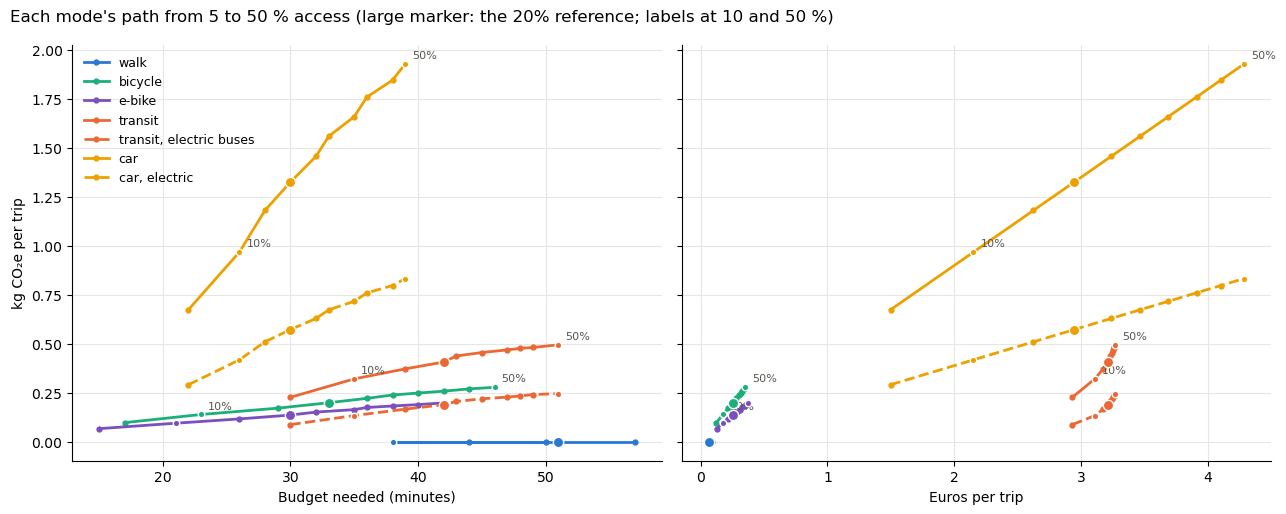

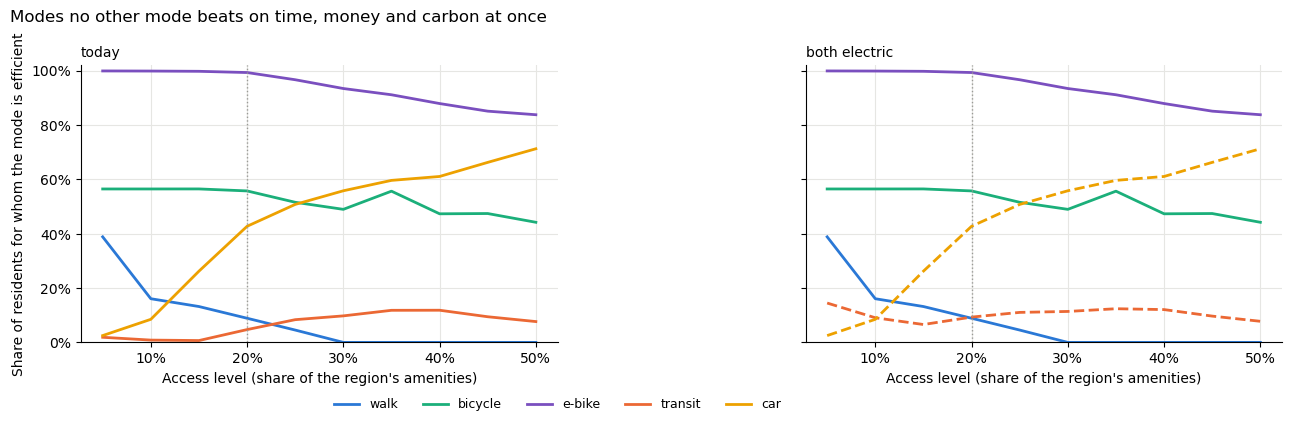

In [10]:
LEVEL_GRID = np.round(np.arange(0.05, 0.55, 0.05), 2)
FLEETS = {"today": ["walk", "bicycle", "e_bike", "transit", "car-ICE"], "both electric": ["walk", "bicycle", "e_bike", "transit-bus-bev", "car-BEV"]}
AXES = ["budget_min", "eur_per_trip", "kg_per_trip"]


def cost_at_level(label, level):
    '''Per hexagon, the budget and the mean trip money and carbon of one mode at one access level.'''
    budget = matching_budget(label, np.full(len(index), level))
    trips = trip_means(label, budget)
    return pd.DataFrame({"budget_min": budget, "eur_per_trip": trips["money"], "kg_per_trip": trips["co2"] / 1000})


started = time.time()
by_level = {(label, level): cost_at_level(label, level) for label in ACCESS_LABELS for level in LEVEL_GRID}
paths = pd.DataFrame([
    {"label": label, "level": level, **{axis: weighted_median(frame[axis], weights) for axis in AXES}}
    for (label, level), frame in by_level.items()
])
print(f"costs on the level grid in {time.time() - started:.0f} s")


def efficient_modes(fleet, level):
    '''Mode by hexagon: True where the mode reaches the level and no other mode of the fleet dominates it.'''
    values = np.stack([by_level[(label, level)][AXES].to_numpy(dtype=float) for label in fleet])
    reaches = np.isfinite(values).all(axis=2)
    values = np.where(np.isfinite(values), values, np.inf)
    dominated = np.zeros(reaches.shape, dtype=bool)
    for i in range(len(fleet)):
        for j in range(len(fleet)):
            if i != j:
                no_worse = (values[j] <= values[i]).all(axis=1)
                better = (values[j] < values[i]).any(axis=1)
                dominated[i] |= reaches[j] & no_worse & better
    return reaches & ~dominated


efficient_share = pd.DataFrame([
    {"fleet": fleet_name, "level": level, **dict(zip(fleet, (efficient_modes(fleet, level) * population).sum(axis=1) / population.sum()))}
    for fleet_name, fleet in FLEETS.items() for level in LEVEL_GRID
]).set_index(["fleet", "level"])

# Frontier paths in the two planes.
LEVEL_MARKS = [0.1, reference_access, 0.5]
figure, axes = plt.subplots(ncols=2, figsize=(13, 5.2), sharey=True)
for axis, (x_axis, xlabel) in zip(axes, [("budget_min", "Budget needed (minutes)"), ("eur_per_trip", "Euros per trip")]):
    for label in ACCESS_LABELS:
        colour, style, name = SERIES[label]
        path = paths.loc[paths["label"] == label].dropna(subset=[x_axis, "kg_per_trip"])
        axis.plot(path[x_axis], path["kg_per_trip"], color=MODE_COLOURS[colour], linestyle=style, linewidth=2, marker="o", markersize=3.5, label=name)
        for level in LEVEL_MARKS:
            point = path.loc[np.isclose(path["level"], level)]
            if len(point):
                axis.scatter(point[x_axis], point["kg_per_trip"], s=55 if level == reference_access else 22, color=MODE_COLOURS[colour],
                             edgecolor="#ffffff", linewidth=1, zorder=3)
                if level != reference_access and label in ("bicycle", "transit", "car-ICE"):
                    axis.annotate(f"{level:.0%}", (point[x_axis].iloc[0], point["kg_per_trip"].iloc[0]), xytext=(5, 4),
                                  textcoords="offset points", fontsize=8, color="#55554f")
    axis.set_xlabel(xlabel)
    axis.grid(color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("kg CO₂e per trip")
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
figure.suptitle(f"Each mode's path from 5 to 50 % access (large marker: the {reference_access:.0%} reference; labels at 10 and 50 %)",
                x=0.01, ha="left")
figure.tight_layout()

# Who is efficient, across levels and fleet states.
figure, axes = plt.subplots(ncols=len(FLEETS), figsize=(13, 4.4), sharey=True)
for axis, (fleet_name, fleet) in zip(axes, FLEETS.items()):
    part = efficient_share.loc[fleet_name]
    for label in fleet:
        colour, style, name = SERIES[label]
        axis.plot(part.index, part[label], color=MODE_COLOURS[colour], linestyle=style, linewidth=2, label=name)
    axis.axvline(reference_access, color="#9a9a96", linewidth=1, linestyle=":")
    axis.set_title(fleet_name, fontsize=10, loc="left")
    axis.set_xlabel("Access level (share of the region's amenities)")
    axis.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axis.set_ylim(0, 1.02)
    axis.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axis.grid(color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Share of residents for whom the mode is efficient")
axes[0].legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(1.0, -0.16), ncol=5)
figure.suptitle("Modes no other mode beats on time, money and carbon at once", x=0.01, ha="left")
figure.tight_layout()

# Pairwise contests against the car at the reference level.
CARBON_MARGIN_KG = 0.25  # the saving per trip an alternative has to deliver to count as cleaner
rows = []
for car_class in PARAMETERS["car_classes"]:
    car = by_level[(car_class, reference_access)]
    for label in ALTERNATIVES:
        other = by_level[(label, reference_access)]
        both = np.isfinite(car[AXES].to_numpy()).all(axis=1) & np.isfinite(other[AXES].to_numpy()).all(axis=1)
        share = lambda mask: (mask & both) @ population / population.sum()
        better = {axis: other[axis].to_numpy() < car[axis].to_numpy() for axis in AXES}
        no_worse = {axis: other[axis].to_numpy() <= car[axis].to_numpy() for axis in AXES}
        rows.append({
            "against": SERIES[car_class][2], "alternative": SERIES[label][2], "both_reach": share(both),
            "less_time": share(better["budget_min"]), "less_money": share(better["eur_per_trip"]),
            f"saves_over_{CARBON_MARGIN_KG}_kg": share((car["kg_per_trip"] - other["kg_per_trip"]).to_numpy() >= CARBON_MARGIN_KG),
            "dominates_car": share(np.logical_and.reduce(list(no_worse.values())) & np.logical_or.reduce(list(better.values()))),
            "dominated_by_car": share(np.logical_and.reduce([~b for b in better.values()]) & np.logical_or.reduce([~n for n in no_worse.values()])),
            "median_kg_saved": weighted_median((car["kg_per_trip"] - other["kg_per_trip"]).where(both), weights),
        })
contests = pd.DataFrame(rows).set_index(["against", "alternative"])
print(f"Shares of all residents at {reference_access:.0%} access. The car's time and money do not depend on its powertrain, "
      f"so only the carbon columns move between the two car classes; an alternative counts as cleaner when it saves at least "
      f"{CARBON_MARGIN_KG} kg per trip.")
contests.round(2)

## 4. Sensitivity: time tolerances of the active modes

Everything above lets a resident walk, cycle or ride an e-bike for up to 60
minutes one way, the same cap as the car and transit. Observed active trips
are much shorter: a median walking trip is about 10 minutes and fewer than one
in five exceeds a mile (Yang & Diez-Roux 2012); most Dutch cycling is under
7.5 km, about 30 minutes at the routed speed (Heinen, van Wee & Maat 2010);
e-bike users report trips of about 10 km against 5 km for cyclists (Castro et
al. 2019); in the Helsinki region the 2018 travel survey puts the average
cycling trip at 19 minutes and 3.4 km and the average walking trip at 20
minutes and 1.3 km (HSL 2019).
This section applies the one-way tolerances in `active_mode_cutoffs_min` to
the active modes only and reports what moves. The e-bike is also shown held to
the bicycle's 30 minutes (`EXTRA_CUTOFFS`), so that its speed and slope advantage
can be told apart from its longer tolerance. The main analysis stays
uncapped; setting `apply_active_cutoffs` to `True` in the parameters applies
the same caps from the start.

Share of residents for whom each mode is efficient at 20% access, before and after the tolerances:


today                                  \
                        uncapped capped capped, e-bike at 30 min   
walk                        0.09   0.00                     0.00   
bicycle                     0.56   0.19                     0.19   
e-bike                      0.99   0.90                     0.55   
transit                     0.05   0.09                     0.42   
car                         0.43   0.43                     0.51   
transit, electric buses      NaN    NaN                      NaN   
car, electric                NaN    NaN                      NaN   

                        both electric                                  
                             uncapped capped capped, e-bike at 30 min  
walk                             0.09   0.00                     0.00  
bicycle                          0.56   0.19                     0.19  
e-bike                           0.99   0.90                     0.55  
transit                           NaN    NaN                      NaN  
car                               NaN    NaN                      NaN  
transit, electric buses          0.09   0.14                     0.46  
car, electric                    0.43   0.43                     0.51

residents_reaching  budget_min  trip_km  \
mode    state                                                       
walk    uncapped                        0.09        51.0     1.71   
        capped at 30 min                0.00         NaN      NaN   
bicycle uncapped                        0.97        33.0     5.39   
        capped at 30 min                0.38        23.0     4.08   
e-bike  uncapped                        0.99        30.0     5.46   
        capped at 45 min                0.90        29.0     5.35   
        capped at 30 min                0.55        24.0     4.66   

                          eur_per_trip  kg_per_trip  access_within_30_min  
mode    state                                                              
walk    uncapped                  0.07         0.00                  0.02  
        capped at 30 min           NaN          NaN                  0.02  
bicycle uncapped                  0.25         0.20                  0.20  
        capped at 30 min          0.19         0.15                  0.20  
e-bike  uncapped                  0.26         0.14                  0.25  
        capped at 45 min          0.25         0.13                  0.25  
        capped at 30 min          0.22         0.12                  0.25

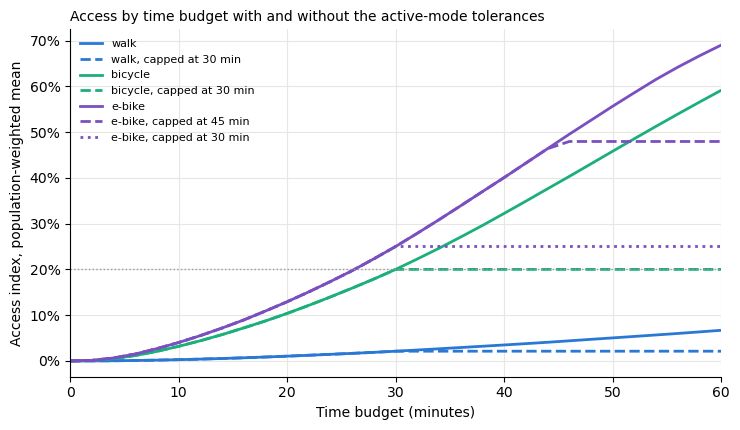

In [11]:
CUTOFFS = PARAMETERS["active_mode_cutoffs_min"]
CAPPED_LABELS = list(CUTOFFS)
# Further tolerances shown beside the main one for comparison: the e-bike held to the
# bicycle's 30 minutes isolates its speed and slope advantage from the longer tolerance.
EXTRA_CUTOFFS = {"e_bike": [30]}


def capped(label, minutes):
    """The cost set of one active mode with trips beyond the tolerance made unreachable."""
    cost = costs[label]
    time = np.where(cost["time"] <= minutes, cost["time"], np.nan).astype(np.float32)
    return {**cost, "time": time}


capped_costs = {label: capped(label, CUTOFFS[label]) for label in CAPPED_LABELS}
states = {
    label: [("uncapped", costs[label]), (f"capped at {CUTOFFS[label]} min", capped_costs[label])]
    + [(f"capped at {minutes} min", capped(label, minutes)) for minutes in EXTRA_CUTOFFS.get(label, [])]
    for label in CAPPED_LABELS
}


def costs_at_reference(cost):
    """Matching budget and mean trip costs at the reference level for one cost set."""
    by_budget = np.stack([access_index(cost["time"] <= budget) for budget in budget_grid])
    enough = by_budget >= reference_access
    budget = np.where(enough.any(axis=0), budget_grid[enough.argmax(axis=0)], np.nan).astype(float)
    reach = cost["time"] <= np.nan_to_num(budget.astype(np.float32), nan=-1.0)[:, None]
    count = reach.sum(axis=1)
    safe = np.where(count > 0, count, 1)
    trips = {currency: np.where(count > 0, (np.nan_to_num(cost[currency]) * reach).sum(axis=1) / safe, np.nan)
             for currency in ["time", "money", "co2", "km"]}
    return budget, trips


rows = []
for label in CAPPED_LABELS:
    for state, cost in states[label]:
        budget, trips = costs_at_reference(cost)
        rows.append({
            "mode": SERIES[label][2], "state": state,
            "residents_reaching": population[~np.isnan(budget)].sum() / population.sum(),
            "budget_min": weighted_median(pd.Series(budget), weights),
            "trip_km": weighted_median(pd.Series(trips["km"]), weights),
            "eur_per_trip": weighted_median(pd.Series(trips["money"]), weights),
            "kg_per_trip": weighted_median(pd.Series(trips["co2"] / 1000), weights),
            f"access_within_{within}_min": population_mean(access_index(cost["time"] <= within)),
        })
cutoff_effect = pd.DataFrame(rows).set_index(["mode", "state"])

# Access by time budget, uncapped solid, capped dashed, the extra tolerances dotted.
STATE_STYLES = ["-", "--", ":"]
figure, axis = plt.subplots(figsize=(7.5, 4.4))
for label in CAPPED_LABELS:
    colour = MODE_COLOURS[SERIES[label][0]]
    for (state, cost), style in zip(states[label], STATE_STYLES):
        values = [population_mean(access_index(cost["time"] <= budget)) for budget in time_grid]
        suffix = "" if state == "uncapped" else f", {state}"
        axis.plot(time_grid, values, color=colour, linestyle=style, linewidth=2, label=SERIES[label][2] + suffix)
axis.axhline(reference_access, color="#9a9a96", linewidth=1, linestyle=":")
axis.set_xlabel("Time budget (minutes)")
axis.set_ylabel("Access index, population-weighted mean")
axis.set_xlim(time_grid[0], time_grid[-1])
axis.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axis.grid(color="#e6e6e3", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
axis.legend(frameon=False, fontsize=8, loc="upper left")
axis.set_title("Access by time budget with and without the active-mode tolerances", fontsize=10, loc="left")
figure.tight_layout()

# Who is efficient at the reference level once the active modes are capped.
def capped_table(cutoffs):
    """The by-level cost table with the active modes capped at the given one-way minutes."""
    table = dict(by_level)
    for label, minutes in cutoffs.items():
        budget, trips = costs_at_reference(capped(label, minutes))
        table[(label, reference_access)] = pd.DataFrame(
            {"budget_min": budget, "eur_per_trip": trips["money"], "kg_per_trip": trips["co2"] / 1000})
    return table


capped_by_level = capped_table(CUTOFFS)
capped_tables = [("uncapped", by_level), ("capped", capped_by_level)] + [
    (f"capped, {SERIES[label][2]} at {minutes} min", capped_table({**CUTOFFS, label: minutes}))
    for label, extra in EXTRA_CUTOFFS.items() for minutes in extra
]


def efficient_modes_from(table, fleet, level):
    """Mode by hexagon: reaches the level and no other mode of the fleet dominates it, from a given cost table."""
    values = np.stack([table[(label, level)][AXES].to_numpy(dtype=float) for label in fleet])
    reaches = np.isfinite(values).all(axis=2)
    values = np.where(np.isfinite(values), values, np.inf)
    dominated = np.zeros(reaches.shape, dtype=bool)
    for i in range(len(fleet)):
        for j in range(len(fleet)):
            if i != j:
                dominated[i] |= reaches[j] & (values[j] <= values[i]).all(axis=1) & (values[j] < values[i]).any(axis=1)
    return reaches & ~dominated


efficient_capped = pd.DataFrame({
    (fleet_name, state): dict(zip([SERIES[l][2] for l in fleet], (efficient_modes_from(table, fleet, reference_access) * population).sum(axis=1) / population.sum()))
    for fleet_name, fleet in FLEETS.items()
    for state, table in capped_tables
})
print(f"Share of residents for whom each mode is efficient at {reference_access:.0%} access, before and after the tolerances:")
display(efficient_capped.round(2))
cutoff_effect.round(2)


## Caveats and next

- One transit departure and one car profile; the car's money is a per-
  kilometre rate (0.36 EUR, the shipped EU average of 2017 adjusted for
  inflation) with no parking fee at the destination, so the car looks cheap
  on the short trips of the reference level, and its time carries a fixed
  300-second parking search that decides the short budgets. A pass-prorated
  fare, a Finnish cost rate, a parking fee and a parking sensitivity would
  all move the results materially.
- Money and emissions are those of the trip to the amenity's hexagon, while
  the time is to the amenity itself; a trip inside the household's own
  hexagon therefore costs nothing but time.
- The access index weighs the eleven categories equally; a household that
  cares about one category (a school, a clinic) faces a different trade-off.
  The same code runs per category by replacing `ONE_HOT` with one column.
- The value of time and the reference carbon price are placeholders to be
  varied, not estimates.
- Next: the gravity version with a shared decay instead of the step budgets,
  the e-bike and the car-occupancy ladder as further fleet states, and the
  ring profiles by distance to the centre.